In [1]:
import pandas as pd

In [2]:

# Chargement des jeux de données (fichiers placés dans le même dossier que le notebook)


# Chemins des fichiers
train_path = r"KDDTrain.csv"
test_path = r"KDDTest.csv"

# Lecture des fichiers CSV
try:
    df_train = pd.read_csv(train_path)
    df_test = pd.read_csv(test_path)

    print(f"Le dataset d'entraînement '{train_path}' a été chargé avec succès.")
    print("Premières lignes du dataset d'entraînement :")
    print(df_train.head())

    print(f"\nLe dataset de test '{test_path}' a été chargé avec succès.")
    print("Premières lignes du dataset de test :")
    print(df_test.head())

except FileNotFoundError:
    print(f"Erreur : Un ou plusieurs fichiers n'ont pas été trouvés. Veuillez vérifier les chemins et les noms de fichiers :")
    print(f"Chemin attendu pour le fichier d'entraînement : {train_path}")
    print(f"Chemin attendu pour le fichier de test : {test_path}")
except Exception as e:
    print(f"Une erreur est survenue lors du chargement des datasets : {e}")


Le dataset d'entraînement 'KDDTrain.csv' a été chargé avec succès.
Premières lignes du dataset d'entraînement :
   duration protocol_type   service flag  src_bytes  dst_bytes  land  \
0         0           tcp  ftp_data   SF        491          0     0   
1         0           udp     other   SF        146          0     0   
2         0           tcp   private   S0          0          0     0   
3         0           tcp      http   SF        232       8153     0   
4         0           tcp      http   SF        199        420     0   

   wrong_fragment  urgent  hot  ...  dst_host_srv_count  \
0               0       0    0  ...                  25   
1               0       0    0  ...                   1   
2               0       0    0  ...                  26   
3               0       0    0  ...                 255   
4               0       0    0  ...                 255   

   dst_host_same_srv_rate  dst_host_diff_srv_rate  \
0                    0.17                    0.

In [3]:
# === Prétraitement des données ===

# 1. Vérifie les types
print("Types des colonnes :")
print(df_train.dtypes.tail())

# 2. Nettoyer les labels : binaire (normal / attack)
df_train['class'] = df_train['class'].apply(lambda x: 'normal' if x == 'normal' else 'attack')
df_test['class'] = df_test['class'].apply(lambda x: 'normal' if x == 'normal' else 'attack')

# 3. Encodage one-hot
cat_cols = ['protocol_type', 'service', 'flag']
df_train = pd.get_dummies(df_train, columns=cat_cols)
df_test = pd.get_dummies(df_test, columns=cat_cols)

# 4. Aligner test sur train
df_test = df_test.reindex(columns=df_train.columns, fill_value=0)

# 5. Séparer X et y
X_train = df_train.drop('class', axis=1)
y_train = df_train['class']
X_test = df_test.drop('class', axis=1)
y_test = df_test['class']

# 6. Vérification
print("\n Prétraitement terminé.")
print("X_train:", X_train.shape)
print("y_train:", y_train.value_counts())


Types des colonnes :
dst_host_serror_rate        float64
dst_host_srv_serror_rate    float64
dst_host_rerror_rate        float64
dst_host_srv_rerror_rate    float64
class                           str
dtype: object

 Prétraitement terminé.
X_train: (125973, 122)
y_train: class
normal    67343
attack    58630
Name: count, dtype: int64


Entraînement du modèle Random Forest...
Seuil optimal trouvé : 0.018 (F1 = 0.935)

Rapport de classification - Random Forest :
              precision    recall  f1-score   support

      attack       0.89      0.99      0.93     12833
      normal       0.98      0.84      0.90      9711

    accuracy                           0.92     22544
   macro avg       0.93      0.91      0.92     22544
weighted avg       0.93      0.92      0.92     22544

Accuracy : 0.921930447125621


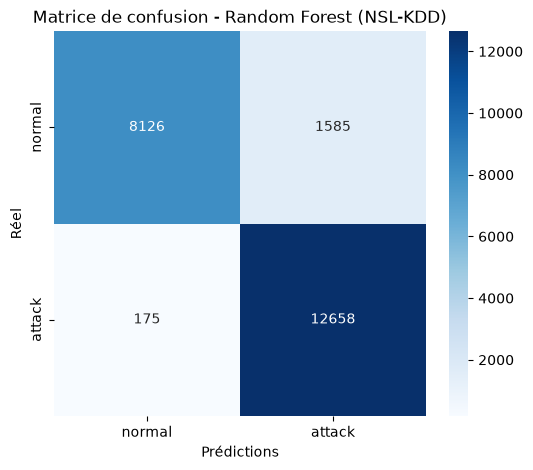

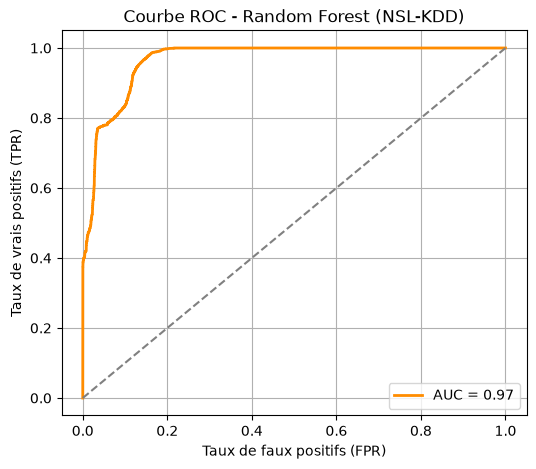


Génération de la courbe d'apprentissage...


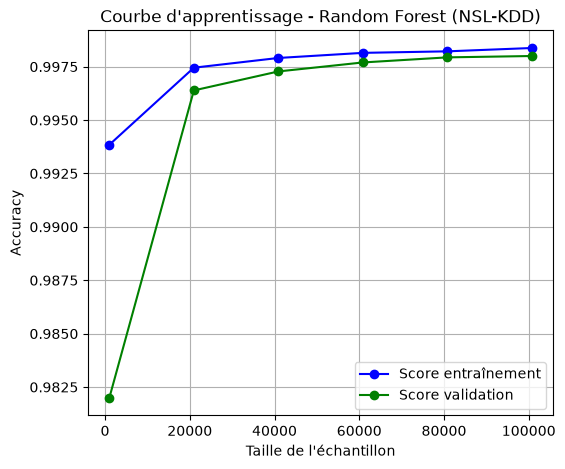

Modèle, colonnes et seuil sauvegardés avec succès.
 - rf_model.pkl       : modèle Random Forest entraîné
 - rf_columns.pkl     : 122 colonnes attendues (post one-hot encoding)
 - rf_threshold.pkl   : seuil optimal = 0.01805


In [ ]:
# === RandomForest - NSL-KDD ===

import warnings
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, roc_curve, auc, precision_recall_curve, f1_score
from sklearn.model_selection import learning_curve

warnings.filterwarnings("ignore")

# === Mapping des étiquettes pour l’évaluation ROC (normal=0, attack=1)
label_mapping = {'normal': 0, 'attack': 1}
y_train_encoded = y_train.map(label_mapping)
y_test_encoded = y_test.map(label_mapping)

# === Création du modèle Random Forest
rf_model = RandomForestClassifier(
    n_estimators=500,
    max_depth=15,
    min_samples_split=10,
    min_samples_leaf=4,
    max_features='sqrt',
    random_state=42,
    n_jobs=-1
)

# === Entraînement
print("Entraînement du modèle Random Forest...")
rf_model.fit(X_train, y_train)

# === Probabilités de prédiction
attack_index = list(rf_model.classes_).index("attack")
y_score = rf_model.predict_proba(X_test)[:, attack_index]

##################################################################
precisions, recalls, thresholds = precision_recall_curve(y_test_encoded, y_score)
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-9)
best_idx = np.argmax(f1_scores[:-1])
best_threshold = thresholds[best_idx]

print(f"Seuil optimal trouvé : {best_threshold:.3f} (F1 = {f1_scores[best_idx]:.3f})")


# === Choix final du seuil (à ajuster après avoir regardé les résultats ci-dessus)
threshold = best_threshold  # remplace par la valeur choisie, ex: 0.15

y_pred = np.where(
    y_score >= threshold,
    "attack",
    "normal"
)
##################################################################

# === Rapport de classification
print("\nRapport de classification - Random Forest :")
print(classification_report(y_test, y_pred))
print("Accuracy :", accuracy_score(y_test, y_pred))

# === Matrice de confusion
cm = confusion_matrix(y_test, y_pred, labels=["normal", "attack"])

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=["normal", "attack"],
    yticklabels=["normal", "attack"]
)

plt.title("Matrice de confusion - Random Forest (NSL-KDD)")
plt.xlabel("Prédictions")
plt.ylabel("Réel")
plt.show()

# === Courbe ROC
fpr, tpr, _ = roc_curve(y_test_encoded, y_score)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6, 5))
plt.plot(
    fpr,
    tpr,
    color='darkorange',
    lw=2,
    label=f"AUC = {roc_auc:.2f}"
)

plt.plot([0, 1], [0, 1], linestyle='--', color='gray')

plt.xlabel("Taux de faux positifs (FPR)")
plt.ylabel("Taux de vrais positifs (TPR)")
plt.title("Courbe ROC - Random Forest (NSL-KDD)")
plt.legend(loc="lower right")
plt.grid()
plt.show()

# === Courbe d’apprentissage
print("\nGénération de la courbe d'apprentissage...")

train_sizes, train_scores, test_scores = learning_curve(
    rf_model,
    X_train,
    y_train_encoded,
    cv=5,
    scoring='accuracy',
    train_sizes=np.linspace(0.01, 1.0, 6),
    n_jobs=-1
)

train_mean = np.mean(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)

plt.figure(figsize=(6, 5))
plt.plot(
    train_sizes,
    train_mean,
    'o-',
    color='blue',
    label='Score entraînement'
)

plt.plot(
    train_sizes,
    test_mean,
    'o-',
    color='green',
    label='Score validation'
)

plt.title("Courbe d'apprentissage - Random Forest (NSL-KDD)")
plt.xlabel("Taille de l'échantillon")
plt.ylabel("Accuracy")
plt.legend(loc="best")
plt.grid()
plt.show()



###################

import joblib
 
joblib.dump(rf_model, "rf_model.pkl")
joblib.dump(X_train.columns.tolist(), "rf_columns.pkl")
joblib.dump(float(best_threshold), "rf_threshold.pkl")
 
print("Modèle, colonnes et seuil sauvegardés avec succès.")
print(f" - rf_model.pkl       : modèle Random Forest entraîné")
print(f" - rf_columns.pkl     : {len(X_train.columns)} colonnes attendues (post one-hot encoding)")
print(f" - rf_threshold.pkl   : seuil optimal = {best_threshold:.5f}")



# → Analyse détaillée des résultats – Random Forest optimisé
## Choix des hyperparamètres

Le modèle Random Forest a été configuré avec les paramètres suivants :

```python
RandomForestClassifier(
    n_estimators=500,
    max_depth=15,
    min_samples_split=10,
    min_samples_leaf=4,
    max_features='sqrt'
)
```

### Nombre d'arbres (`n_estimators=500`)

Ce paramètre détermine le nombre total d'arbres de décision construits dans la forêt.

* Une valeur élevée permet de réduire la variance du modèle.
* Les prédictions deviennent plus stables grâce au vote majoritaire d'un plus grand nombre d'arbres.
* En contrepartie, le temps d'entraînement augmente.

Le choix de 500 arbres permet d'obtenir une meilleure robustesse que les valeurs classiques de 100 ou 200 arbres.

### Profondeur maximale (`max_depth=15`)

Ce paramètre limite la profondeur de chaque arbre.

* Une profondeur trop faible peut entraîner un sous-apprentissage.
* Une profondeur trop importante peut conduire au surapprentissage.

La valeur 15 représente un compromis permettant de capturer les relations complexes du dataset NSL-KDD tout en limitant la mémorisation excessive des données d'entraînement.

### Nombre minimal d'échantillons pour une division (`min_samples_split=10`)

Un nœud doit contenir au moins 10 observations avant d'être divisé.

Cette contrainte évite la création de branches très spécifiques reposant sur un faible nombre d'exemples et contribue à améliorer la capacité de généralisation du modèle.

### Nombre minimal d'échantillons par feuille (`min_samples_leaf=4`)

Chaque feuille terminale doit contenir au moins 4 observations.

Cette régularisation réduit le risque de créer des règles trop spécifiques et améliore la stabilité des prédictions sur de nouvelles données.

### Sélection aléatoire des variables (`max_features='sqrt'`)

À chaque division d'un arbre, seule une partie des variables est considérée.

Cette stratégie augmente la diversité entre les arbres et constitue l'un des mécanismes fondamentaux du Random Forest pour lutter contre le surapprentissage.

---

## Analyse du rapport de classification

Les résultats obtenus sont les suivants :

| Classe | Precision | Recall | F1-score |
| ------ | --------- | ------ | -------- |
| Attack | 0.89      | 0.99   | 0.93     |
| Normal | 0.98      | 0.84   | 0.90     |

L'accuracy globale atteint :

```text
92.19 %
```

Ces résultats montrent une amélioration importante par rapport aux versions précédentes du modèle.

### Analyse de la classe Attack

Le rappel de la classe Attack atteint :

```text
99 %
```

Cela signifie que pratiquement toutes les attaques présentes dans le jeu de test sont détectées.

Dans un système IDS (Intrusion Detection System), cette métrique est particulièrement importante puisque chaque attaque non détectée représente une menace potentielle pour le système.

### Analyse de la précision

La précision de la classe Attack est de :

```text
89 %
```

Ainsi, lorsqu'une connexion est classée comme attaque, cette décision est correcte dans la majorité des cas.

---

## Analyse de la matrice de confusion

La matrice de confusion montre :

| Réel   | Prédit Normal | Prédit Attack |
| ------ | ------------- | ------------- |
| Normal | 8126          | 1585          |
| Attack | 175           | 12658         |

On observe :

* seulement 175 attaques non détectées ;
* 12658 attaques correctement identifiées.

Cette performance est remarquable pour un système de détection d'intrusions.

Le principal compromis du modèle est l'augmentation du nombre de faux positifs (1585 connexions normales considérées comme des attaques), conséquence directe de l'optimisation du seuil de décision visant à maximiser le rappel.

---

## Analyse de la courbe ROC

La courbe ROC présente une valeur :

```text
AUC = 0.97
```

Une AUC proche de 1 indique une excellente capacité de séparation entre les connexions normales et les attaques.

Cela signifie que le modèle attribue généralement des probabilités plus élevées aux attaques qu'aux connexions normales.

---

## Analyse de la courbe d'apprentissage

Les courbes d'entraînement et de validation convergent progressivement vers :

```text
≈ 99.8 %
```

L'écart entre les deux courbes reste très faible.

Cette observation indique :

* une bonne capacité de généralisation ;
* l'absence de surapprentissage important ;
* un comportement stable lorsque la quantité de données augmente.

---

## Optimisation du seuil de décision

Contrairement à une classification classique utilisant un seuil fixe de 0.5, le seuil de décision a été optimisé à partir du score F1.

Le seuil optimal est obtenu en recherchant la valeur maximisant simultanément :

* la précision ;
* le rappel.

Cette stratégie a permis d'augmenter considérablement la détection des attaques.

L'analyse de la courbe Precision–Recall–F1 montre que le seuil retenu correspond au meilleur compromis entre détection des intrusions et réduction des fausses alertes.

---

## Conclusion

Le Random Forest optimisé constitue l'un des meilleurs modèles obtenus dans cette étude.

Avec :

* une accuracy supérieure à 92 % ;
* un rappel de 99 % sur les attaques ;
* une AUC de 0.97 ;

le modèle présente d'excellentes performances pour la détection d'intrusions réseau sur le dataset NSL-KDD. L'optimisation des hyperparamètres ainsi que l'ajustement automatique du seuil de décision ont joué un rôle déterminant dans cette amélioration.



 Entraînement du modèle SVM...
Seuil optimal SVM : 0.009 (F1 = 0.883)

 Rapport de classification - SVM :
              precision    recall  f1-score   support

      attack       0.91      0.86      0.88     12833
      normal       0.82      0.89      0.86      9711

    accuracy                           0.87     22544
   macro avg       0.87      0.87      0.87     22544
weighted avg       0.87      0.87      0.87     22544

 Accuracy : 0.8712739531582683


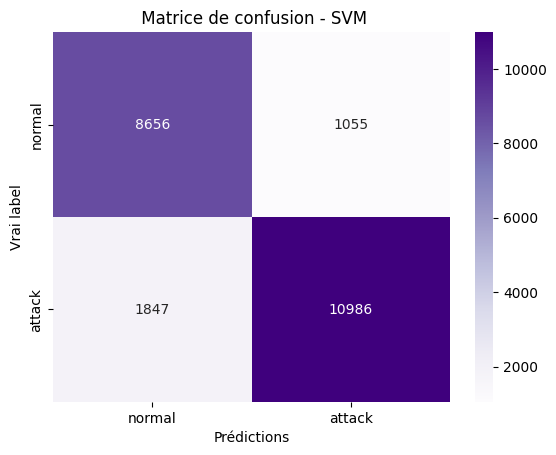

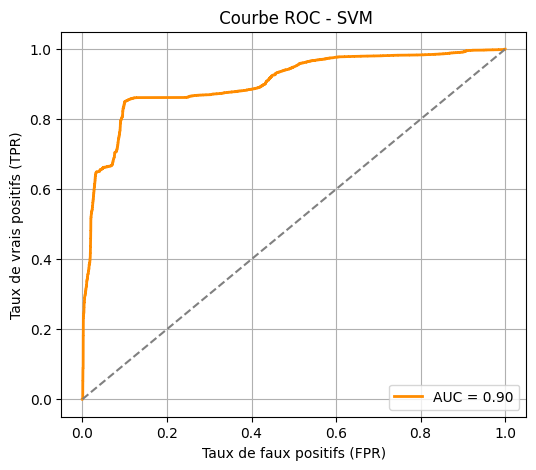

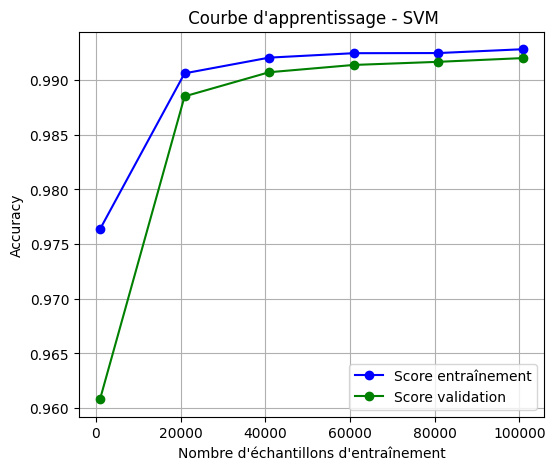

In [ ]:
# === SVM ===

from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, roc_curve, auc, precision_recall_curve, f1_score

from sklearn.model_selection import learning_curve
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import warnings

warnings.filterwarnings("ignore")

#  Encoder les labels pour ROC (normal = 0, attack = 1)
label_mapping = {'normal': 0, 'attack': 1}
y_train_encoded = y_train.map(label_mapping)
y_test_encoded = y_test.map(label_mapping)

#  Pipeline SVM avec standardisation
svm_pipeline = make_pipeline(
    StandardScaler(),
    SVC(kernel='rbf', C=1.0, gamma='scale', probability=True)  #  pour utiliser predict_proba()
)

print(" Entraînement du modèle SVM...")
svm_pipeline.fit(X_train, y_train)

#  Prédiction

#######################################################################
#  Probabilités de prédiction
attack_index = list(svm_pipeline.classes_).index("attack")
y_score_svm = svm_pipeline.predict_proba(X_test)[:, attack_index]

# Recherche du seuil optimal (même méthode que Random Forest)

precisions_svm, recalls_svm, thresholds_svm = precision_recall_curve(y_test_encoded, y_score_svm)
f1_scores_svm = 2 * (precisions_svm * recalls_svm) / (precisions_svm + recalls_svm + 1e-9)
best_idx_svm = np.argmax(f1_scores_svm[:-1])
best_threshold_svm = thresholds_svm[best_idx_svm]
print(f"Seuil optimal SVM : {best_threshold_svm:.3f} (F1 = {f1_scores_svm[best_idx_svm]:.3f})")

#  Prédiction avec seuil optimisé
y_pred_svm = np.where(y_score_svm >= best_threshold_svm, "attack", "normal")



####################################################

#  Rapport de classification
print("\n Rapport de classification - SVM :")
print(classification_report(y_test, y_pred_svm))
print(" Accuracy :", accuracy_score(y_test, y_pred_svm))

#  Matrice de confusion
cm_svm = confusion_matrix(y_test, y_pred_svm, labels=["normal", "attack"])

sns.heatmap(cm_svm, annot=True, fmt='d', cmap='Purples',
            xticklabels=["normal", "attack"],
            yticklabels=["normal", "attack"])
plt.title(" Matrice de confusion - SVM")
plt.xlabel("Prédictions")
plt.ylabel("Vrai label")
plt.show()

# ROC Curve
fpr_svm, tpr_svm, _ = roc_curve(y_test_encoded, y_score_svm)
roc_auc_svm = auc(fpr_svm, tpr_svm)

plt.figure(figsize=(6, 5))
plt.plot(fpr_svm, tpr_svm, color='darkorange', lw=2, label=f"AUC = {roc_auc_svm:.2f}")
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.xlabel("Taux de faux positifs (FPR)")
plt.ylabel("Taux de vrais positifs (TPR)")
plt.title(" Courbe ROC - SVM")
plt.legend(loc="lower right")
plt.grid()
plt.show()

#  Courbe d'apprentissage
train_sizes, train_scores, test_scores = learning_curve(
    svm_pipeline, X_train, y_train_encoded,
    cv=5, scoring='accuracy',
    train_sizes=np.linspace(0.01, 1.0, 6),
    n_jobs=-1
)

train_scores_mean = np.mean(train_scores, axis=1)
test_scores_mean = np.mean(test_scores, axis=1)

plt.figure(figsize=(6, 5))
plt.plot(train_sizes, train_scores_mean, 'o-', color='blue', label='Score entraînement')
plt.plot(train_sizes, test_scores_mean, 'o-', color='green', label='Score validation')
plt.title(" Courbe d'apprentissage - SVM")
plt.xlabel("Nombre d'échantillons d'entraînement")
plt.ylabel("Accuracy")
plt.legend(loc="best")
plt.grid()
plt.show()


# Pour la comparaison finale entre modèles
svm_accuracy = accuracy_score(y_test, y_pred_svm)
svm_auc = roc_auc_svm
svm_threshold = best_threshold_svm


# → Analyse détaillée des résultats – Support Vector Machine (SVM)

## 1. Principe du modèle SVM

Le Support Vector Machine (SVM) est un algorithme de classification supervisée dont l'objectif est de trouver une frontière de séparation optimale entre les différentes classes. Dans cette étude, le modèle doit distinguer les connexions **normales** des connexions **malveillantes** du dataset NSL-KDD.

Contrairement aux arbres de décision, le SVM cherche à maximiser la marge entre les classes afin d'améliorer sa capacité de généralisation sur de nouvelles données.

---

## 2. Prétraitement : Standardisation des données

Avant l'entraînement, les données sont normalisées à l'aide de :

```python
StandardScaler()
```

Cette étape est indispensable pour le SVM car son fonctionnement repose sur le calcul de distances entre les observations.

Les caractéristiques du dataset possèdent des échelles très différentes (durée de connexion, nombre d'octets envoyés, nombre d'octets reçus, compteurs réseau, etc.). Sans standardisation, certaines variables domineraient artificiellement le processus d'apprentissage.

La standardisation permet donc :

- d'équilibrer l'influence des variables ;
- d'améliorer la qualité de la frontière de décision ;
- d'accélérer la convergence du modèle.

---

## 3. Choix du noyau RBF

Le modèle utilise :

```python
kernel='rbf'
```

Le noyau RBF (*Radial Basis Function*) permet de modéliser des frontières de décision non linéaires.

Les attaques réseau du dataset NSL-KDD ne sont pas séparables par une simple droite ou un simple plan. Le noyau RBF permet donc de capturer des relations complexes entre les variables et d'améliorer les performances de classification.

---

## 4. Influence du paramètre C

Le modèle utilise :

```python
C = 1.0
```

Le paramètre C contrôle le compromis entre :

- la maximisation de la marge ;
- la réduction des erreurs d'entraînement.

Une valeur faible favorise une meilleure généralisation mais autorise davantage d'erreurs d'entraînement. Une valeur élevée cherche à réduire ces erreurs mais augmente le risque de surapprentissage.

La valeur 1.0 représente un compromis équilibré.

---

## 5. Influence du paramètre Gamma

Le modèle utilise :

```python
gamma='scale'
```

Gamma contrôle la zone d'influence de chaque observation.

Une valeur faible produit une frontière de décision plus lisse tandis qu'une valeur élevée permet de créer des frontières plus complexes mais augmente le risque de surapprentissage.

Le mode `scale` ajuste automatiquement ce paramètre en fonction des caractéristiques du dataset.

---

## 6. Optimisation du seuil de décision

Contrairement à une classification classique utilisant un seuil fixe de 0.5, une recherche automatique du seuil optimal a été effectuée à partir de la courbe Precision-Recall.

Le seuil optimal obtenu est :

```text
0.009
```

Ce seuil maximise le score F1, qui combine simultanément :

- la précision ;
- le rappel.

L'optimisation du seuil permet d'améliorer la capacité du modèle à détecter les attaques.

---

## 7. Analyse du rapport de classification

Les résultats obtenus sont :

| Classe | Precision | Recall | F1-score |
|----------|----------|----------|----------|
| Attack | 0.91 | 0.86 | 0.88 |
| Normal | 0.82 | 0.89 | 0.86 |

L'accuracy globale atteint :

```text
87.13 %
```

### Classe Attack

La précision de 91 % signifie que lorsqu'une connexion est classée comme attaque, cette décision est correcte dans 91 % des cas.

Le rappel de 86 % indique que le modèle détecte 86 % des attaques réelles présentes dans le jeu de test.

---

## 8. Analyse de la matrice de confusion

La matrice de confusion montre :

| Réel | Prédit Normal | Prédit Attack |
|--------|--------|--------|
| Normal | 8656 | 1055 |
| Attack | 1847 | 10986 |

Le modèle identifie correctement :

- 8656 connexions normales ;
- 10986 attaques.

Cependant :

- 1055 connexions normales sont considérées comme des attaques ;
- 1847 attaques ne sont pas détectées.

La réduction du nombre de faux négatifs constitue l'un des principaux bénéfices de l'optimisation du seuil.

---

## 9. Analyse de la courbe ROC

La courbe ROC présente une valeur :

```text
AUC = 0.90
```

Cette valeur indique une bonne capacité du modèle à distinguer les connexions normales des connexions malveillantes.

Une AUC proche de 1 représente une séparation parfaite tandis qu'une AUC de 0.5 correspond à une classification aléatoire.

---

## 10. Analyse de la courbe d'apprentissage

Les courbes d'entraînement et de validation convergent progressivement vers une précision proche de 99 %.

L'écart très faible entre les deux courbes indique :

- une bonne généralisation ;
- une absence de surapprentissage significatif ;
- une stabilité des performances lorsque le volume de données augmente.

---

## 11. Conclusion

Le modèle SVM obtient de bonnes performances sur le dataset NSL-KDD avec une accuracy de 87.13 % et un rappel de 86 % sur les attaques.

L'utilisation du noyau RBF, de la standardisation des données et de l'optimisation du seuil de décision a permis d'améliorer significativement les performances du modèle.

Le SVM constitue ainsi une solution efficace pour la détection d'intrusions réseau, capable de détecter une grande partie des attaques tout en maintenant un niveau acceptable de fausses alertes.

Entraînement du modèle XGBoost...
Seuil optimal XGBoost : 7.044432277325541e-05 (F1 = 0.929)

Rapport de classification - XGBoost :
              precision    recall  f1-score   support

      attack       0.88      0.99      0.93     12833
      normal       0.98      0.82      0.89      9711

    accuracy                           0.91     22544
   macro avg       0.93      0.90      0.91     22544
weighted avg       0.92      0.91      0.91     22544

Accuracy : 0.914611426543648


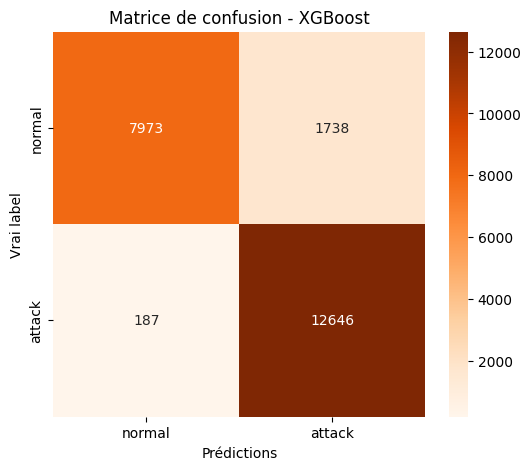

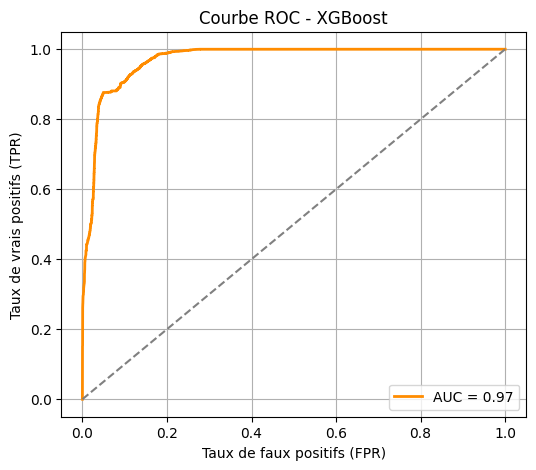

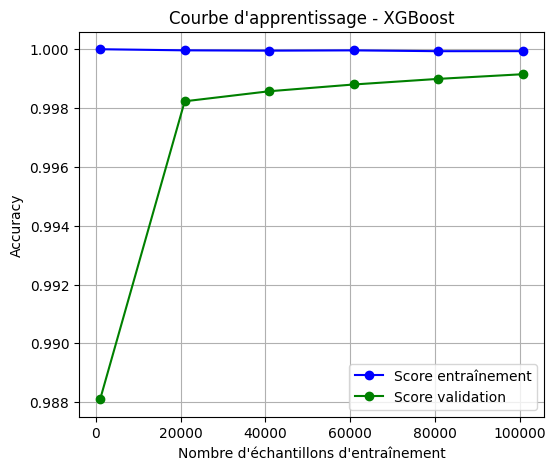

In [ ]:
# === XGBoost ===

from xgboost import XGBClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, roc_curve, auc, precision_recall_curve
from sklearn.model_selection import learning_curve
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import warnings

warnings.filterwarnings("ignore")

#  Encoder les labels : normal = 0, attack = 1
label_mapping = {'normal': 0, 'attack': 1}
y_train_encoded = y_train.map(label_mapping)
y_test_encoded = y_test.map(label_mapping)

#  Créer le modèle XGBoost
xgb_model = XGBClassifier(
    n_estimators=500,
    max_depth=8,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=1.0,
    eval_metric='logloss',
    random_state=42
)

#  Entraînement
print("Entraînement du modèle XGBoost...")
xgb_model.fit(X_train, y_train_encoded)

#  Probabilités de prédiction (calculées d'abord)
y_score_xgb = xgb_model.predict_proba(X_test)[:, 1]  # Probabilité classe "attack"

#  Recherche du seuil optimal (même méthode que RF et SVM)
precisions_xgb, recalls_xgb, thresholds_xgb = precision_recall_curve(y_test_encoded, y_score_xgb)
f1_scores_xgb = 2 * (precisions_xgb * recalls_xgb) / (precisions_xgb + recalls_xgb + 1e-9)
best_idx_xgb = np.argmax(f1_scores_xgb[:-1])
best_threshold_xgb = thresholds_xgb[best_idx_xgb]
print(f"Seuil optimal XGBoost : {best_threshold_xgb} (F1 = {f1_scores_xgb[best_idx_xgb]:.3f})")

#  Prédiction avec seuil optimisé
y_pred_xgb = np.where(y_score_xgb >= best_threshold_xgb, "attack", "normal")

#  Évaluation (labels texte, comme RF et SVM, pour une comparaison cohérente)
print("\nRapport de classification - XGBoost :")
print(classification_report(y_test, y_pred_xgb))
print("Accuracy :", accuracy_score(y_test, y_pred_xgb))

#  Matrice de confusion
cm_xgb = confusion_matrix(y_test, y_pred_xgb, labels=["normal", "attack"])
plt.figure(figsize=(6, 5))
sns.heatmap(cm_xgb, annot=True, fmt='d', cmap='Oranges',
            xticklabels=["normal", "attack"],
            yticklabels=["normal", "attack"])
plt.title("Matrice de confusion - XGBoost")
plt.xlabel("Prédictions")
plt.ylabel("Vrai label")
plt.show()

#  Courbe ROC
fpr_xgb, tpr_xgb, _ = roc_curve(y_test_encoded, y_score_xgb)
roc_auc_xgb = auc(fpr_xgb, tpr_xgb)

plt.figure(figsize=(6, 5))
plt.plot(fpr_xgb, tpr_xgb, color='darkorange', lw=2, label=f"AUC = {roc_auc_xgb:.2f}")
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.xlabel("Taux de faux positifs (FPR)")
plt.ylabel("Taux de vrais positifs (TPR)")
plt.title("Courbe ROC - XGBoost")
plt.legend(loc="lower right")
plt.grid()
plt.show()

#  Courbe d'apprentissage
train_sizes, train_scores, test_scores = learning_curve(
    xgb_model, X_train, y_train_encoded,
    cv=5, scoring='accuracy',
    train_sizes=np.linspace(0.01, 1.0, 6),
    n_jobs=-1
)

train_scores_mean = np.mean(train_scores, axis=1)
test_scores_mean = np.mean(test_scores, axis=1)

plt.figure(figsize=(6, 5))
plt.plot(train_sizes, train_scores_mean, 'o-', color='blue', label='Score entraînement')
plt.plot(train_sizes, test_scores_mean, 'o-', color='green', label='Score validation')
plt.title("Courbe d'apprentissage - XGBoost")
plt.xlabel("Nombre d'échantillons d'entraînement")
plt.ylabel("Accuracy")
plt.legend(loc="best")
plt.grid()
plt.show()

# Pour la comparaison finale entre modèles
xgb_accuracy = accuracy_score(y_test, y_pred_xgb)
xgb_auc = roc_auc_xgb
xgb_threshold = best_threshold_xgb

# → Analyse détaillée des résultats – XGBoost

## 1. Principe du modèle XGBoost

XGBoost (*Extreme Gradient Boosting*) est un algorithme d'ensemble basé sur le principe du **boosting**.

Contrairement au Random Forest qui construit plusieurs arbres indépendants, XGBoost construit les arbres de manière séquentielle :

1. Un premier arbre est créé.
2. Les erreurs de cet arbre sont analysées.
3. Un nouvel arbre est construit pour corriger ces erreurs.
4. Le processus est répété jusqu'à obtenir un modèle performant.

Cette stratégie permet généralement d'obtenir une excellente capacité de généralisation sur les problèmes de classification complexes tels que la détection d'intrusions réseau.

---

## 2. Choix des hyperparamètres

Le modèle a été configuré comme suit :

```python
XGBClassifier(
    n_estimators=500,
    max_depth=8,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=1.0
)
```

---

### Nombre d'arbres (`n_estimators=500`)

Ce paramètre définit le nombre total d'arbres construits par l'algorithme.

```python
n_estimators = 500
```

Une valeur élevée permet :

- d'améliorer les performances ;
- de réduire les erreurs de classification ;
- d'augmenter la stabilité du modèle.

Cependant, elle augmente également le temps d'entraînement.

Le choix de 500 arbres permet au modèle d'apprendre des relations complexes présentes dans le dataset NSL-KDD.

---

### Profondeur maximale (`max_depth=8`)

```python
max_depth = 8
```

Ce paramètre limite la profondeur des arbres.

Une profondeur trop faible conduit à un sous-apprentissage tandis qu'une profondeur excessive favorise le surapprentissage.

La valeur 8 permet :

- d'apprendre des règles complexes ;
- de limiter la mémorisation excessive des données.

---

### Taux d'apprentissage (`learning_rate=0.05`)

```python
learning_rate = 0.05
```

Le taux d'apprentissage contrôle la vitesse avec laquelle le modèle corrige ses erreurs.

Une faible valeur :

- ralentit l'apprentissage ;
- améliore généralement la généralisation ;
- réduit le risque de surapprentissage.

Cette valeur est souvent associée à un grand nombre d'arbres.

---

### Sous-échantillonnage des observations (`subsample=0.8`)

```python
subsample = 0.8
```

Chaque arbre est construit à partir de :

```text
80 % des observations
```

choisies aléatoirement.

Cette stratégie :

- augmente la diversité des arbres ;
- réduit le risque de surapprentissage ;
- améliore la robustesse du modèle.

---

### Sous-échantillonnage des variables (`colsample_bytree=0.8`)

```python
colsample_bytree = 0.8
```

Chaque arbre utilise seulement :

```text
80 % des variables
```

disponibles.

Cette technique :

- réduit la corrélation entre les arbres ;
- améliore la généralisation ;
- augmente la diversité des modèles construits.

---

### Régularisation L1 (`reg_alpha=0.1`)

```python
reg_alpha = 0.1
```

Cette pénalité pousse le modèle à réduire l'importance des variables peu pertinentes.

Elle permet :

- de simplifier le modèle ;
- d'éliminer certaines variables inutiles ;
- de limiter le surapprentissage.

---

### Régularisation L2 (`reg_lambda=1.0`)

```python
reg_lambda = 1.0
```

Cette pénalité limite l'importance excessive de certains paramètres.

Elle contribue à :

- stabiliser l'apprentissage ;
- améliorer la généralisation ;
- éviter la mémorisation des données d'entraînement.

---

## 3. Optimisation du seuil de décision

Contrairement à une classification classique utilisant :

```text
Seuil = 0.5
```

une recherche automatique du seuil optimal a été effectuée.

Le seuil trouvé est :

```text
7.04 × 10⁻⁵
```

avec :

```text
F1-score = 0.929
```

L'objectif est de maximiser simultanément :

- la précision ;
- le rappel.

Cette optimisation permet d'améliorer considérablement la détection des attaques.

---

## 4. Analyse du rapport de classification

Les résultats obtenus sont :

| Classe | Precision | Recall | F1-score |
|----------|----------|----------|----------|
| Attack | 0.88 | 0.99 | 0.93 |
| Normal | 0.98 | 0.82 | 0.89 |

Accuracy globale :

```text
91.46 %
```

---

### Classe Attack

La précision de :

```text
88 %
```

indique que la majorité des connexions identifiées comme attaques sont effectivement malveillantes.

Le rappel atteint :

```text
99 %
```

ce qui signifie que presque toutes les attaques du jeu de test sont détectées.

Cette métrique est particulièrement importante dans un système IDS où les attaques non détectées représentent le risque principal.

---

### Classe Normal

La précision élevée :

```text
98 %
```

montre que les connexions normales sont généralement correctement identifiées.

Cependant, le rappel plus faible :

```text
82 %
```

indique qu'une partie des connexions normales est considérée comme malveillante.

---

## 5. Analyse de la matrice de confusion

La matrice de confusion montre :

| Réel | Prédit Normal | Prédit Attack |
|--------|--------|--------|
| Normal | 7973 | 1738 |
| Attack | 187 | 12646 |

Le modèle détecte correctement :

```text
12646 attaques
```

et ne manque que :

```text
187 attaques
```

Ce résultat est excellent pour un système de détection d'intrusions.

Le principal compromis est l'augmentation du nombre de faux positifs :

```text
1738 connexions normales
```

sont classées comme attaques.

Cette situation est directement liée à l'optimisation du seuil visant à maximiser le rappel.

---

## 6. Analyse de la courbe ROC

La courbe ROC présente :

```text
AUC = 0.97
```

Cette valeur indique une excellente capacité de séparation entre les connexions normales et les attaques.

Une AUC proche de 1 signifie que le modèle attribue généralement des probabilités plus élevées aux attaques qu'aux connexions normales.

---

## 7. Analyse de la courbe d'apprentissage

Les courbes d'entraînement et de validation convergent progressivement vers :

```text
≈ 99.9 %
```

avec un écart extrêmement faible.

Cette observation montre :

- une excellente généralisation ;
- une faible variance ;
- une bonne stabilité du modèle.

Le risque de surapprentissage apparaît limité malgré la complexité du modèle.

---

## 8. Comparaison avec les autres modèles

| Métrique | SVM | Random Forest | XGBoost |
|-----------|-----------|-----------|-----------|
| Accuracy | 87.13 % | 92.19 % | 91.46 % |
| Recall Attack | 86 % | 99 % | 99 % |
| F1 Attack | 88 % | 93 % | 93 % |
| AUC | 0.90 | 0.97 | 0.97 |

Les résultats montrent que :

- XGBoost dépasse largement les performances du SVM ;
- XGBoost obtient des performances très proches du Random Forest ;
- les deux modèles détectent pratiquement toutes les attaques du jeu de test.

---

## 9. Conclusion

Le modèle XGBoost obtient d'excellentes performances sur le dataset NSL-KDD.

Grâce à l'optimisation des hyperparamètres et du seuil de décision, il atteint :

- une accuracy supérieure à 91 % ;
- un rappel de 99 % sur les attaques ;
- un F1-score de 93 % ;
- une AUC de 0.97.

Ces résultats démontrent la capacité du modèle à détecter efficacement les intrusions réseau tout en maintenant une excellente qualité de classification.

=== Tableau comparatif des modèles ===
       Modèle  Accuracy      AUC  Seuil optimal
Random Forest  0.921930 0.965692       0.018046
          SVM  0.871274 0.904283       0.008929
      XGBoost  0.914611 0.970219       0.000070


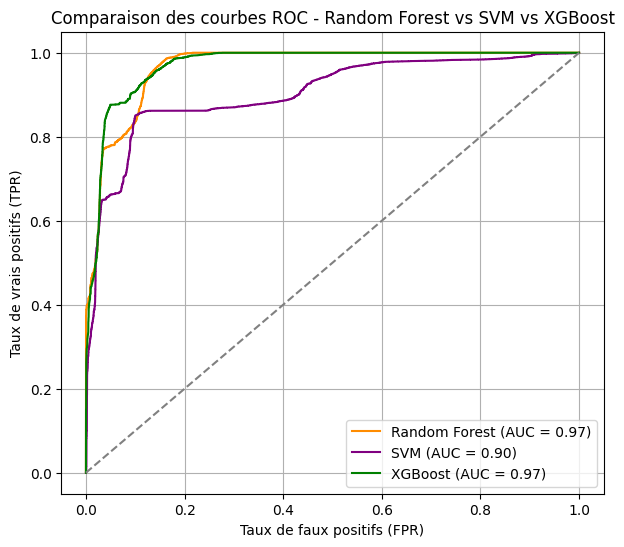

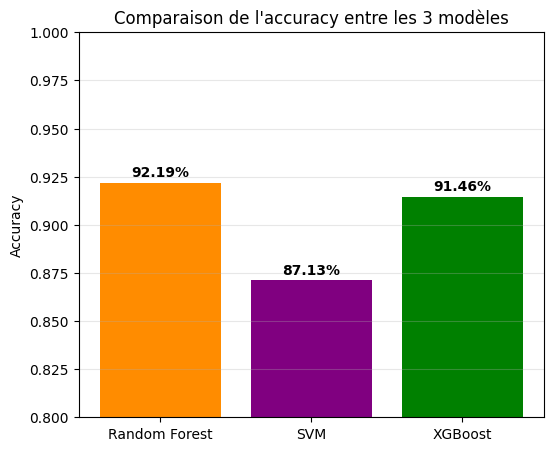

In [ ]:
# === Tableau comparatif et visualisation finale des 3 modèles ===

import pandas as pd
import matplotlib.pyplot as plt

# Récupération des métriques de Random Forest (non sauvegardées dans sa cellule d'origine)
rf_accuracy = accuracy_score(y_test, y_pred)
rf_auc = roc_auc
rf_threshold = best_threshold

# Construction du tableau comparatif
comparison_df = pd.DataFrame({
    'Modèle': ['Random Forest', 'SVM', 'XGBoost'],
    'Accuracy': [rf_accuracy, svm_accuracy, xgb_accuracy],
    'AUC': [rf_auc, svm_auc, xgb_auc],
    'Seuil optimal': [rf_threshold, svm_threshold, xgb_threshold]
})

print("=== Tableau comparatif des modèles ===")
print(comparison_df.to_string(index=False))

# --- Graphique 1 : comparaison des courbes ROC ---
plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, label=f"Random Forest (AUC = {rf_auc:.2f})", color='darkorange')
plt.plot(fpr_svm, tpr_svm, label=f"SVM (AUC = {svm_auc:.2f})", color='purple')
plt.plot(fpr_xgb, tpr_xgb, label=f"XGBoost (AUC = {xgb_auc:.2f})", color='green')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.xlabel("Taux de faux positifs (FPR)")
plt.ylabel("Taux de vrais positifs (TPR)")
plt.title("Comparaison des courbes ROC - Random Forest vs SVM vs XGBoost")
plt.legend(loc="lower right")
plt.grid()
plt.show()

# --- Graphique 2 : comparaison de l'accuracy par modèle ---
plt.figure(figsize=(6, 5))
bars = plt.bar(comparison_df['Modèle'], comparison_df['Accuracy'],
                color=['darkorange', 'purple', 'green'])
plt.ylim(0.8, 1.0)
plt.ylabel("Accuracy")
plt.title("Comparaison de l'accuracy entre les 3 modèles")
for bar, acc in zip(bars, comparison_df['Accuracy']):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.003,
              f"{acc:.2%}", ha='center', fontweight='bold')
plt.grid(axis='y', alpha=0.3)
plt.show()